In [ ]:
# ============================================================
# THREATLENS - TASK 6
# STEPS 1-8: LOAD AND VERIFY TASK 5 OUTPUT
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("THREATLENS - TASK 6")
print("Loading and Verifying Task 5 Output")
print("=" * 70)


# ============================================================
# STEP 1 - LOAD THE FOUR CSV FILES
# ============================================================

print("\n[STEP 1] Loading Task 5 files...")

X_train_final = pd.read_csv(
    "/content/ThreatLens_X_train.csv"
)

X_test_final = pd.read_csv(
    "/content/ThreatLens_X_test.csv"
)

y_train_encoded = pd.read_csv(
    "/content/ThreatLens_y_train.csv"
)

y_test_encoded = pd.read_csv(
    "/content/ThreatLens_y_test.csv"
)

print("✓ X_train loaded")
print("✓ X_test loaded")
print("✓ y_train loaded")
print("✓ y_test loaded")


# ============================================================
# STEP 2 - DISPLAY ORIGINAL SHAPES
# ============================================================

print("\n[STEP 2] Original dataset shapes")

print("X_train:", X_train_final.shape)
print("X_test :", X_test_final.shape)
print("y_train:", y_train_encoded.shape)
print("y_test :", y_test_encoded.shape)


# ============================================================
# STEP 3 - REMOVE UNNECESSARY INDEX COLUMNS
# ============================================================

print("\n[STEP 3] Checking for unnecessary index columns...")

# Automatically detect common pandas index columns
index_columns = [
    col for col in X_train_final.columns
    if col.lower().startswith("unnamed")
]

if len(index_columns) > 0:

    print("Found index column(s):", index_columns)

    X_train_final = X_train_final.drop(
        columns=index_columns
    )

    # Remove the same columns from X_test if present
    X_test_final = X_test_final.drop(
        columns=[
            col for col in index_columns
            if col in X_test_final.columns
        ]
    )

    print("✓ Index column(s) removed")

else:

    print("✓ No unnecessary index column found")


# ============================================================
# STEP 4 - CONVERT TARGET DATAFRAME TO SERIES
# ============================================================

print("\n[STEP 4] Preparing target variables...")

print("y_train columns:", y_train_encoded.columns.tolist())
print("y_test columns :", y_test_encoded.columns.tolist())

# Make sure each target CSV contains one target column
if y_train_encoded.shape[1] != 1:
    raise ValueError(
        "y_train contains more than one column. "
        "Check the Task 5 output."
    )

if y_test_encoded.shape[1] != 1:
    raise ValueError(
        "y_test contains more than one column. "
        "Check the Task 5 output."
    )

# Convert DataFrame → Series
y_train_encoded = y_train_encoded.iloc[:, 0]
y_test_encoded = y_test_encoded.iloc[:, 0]

print("✓ y_train converted to 1D Series")
print("✓ y_test converted to 1D Series")


# ============================================================
# STEP 5 - VERIFY FINAL SHAPES
# ============================================================

print("\n[STEP 5] Final shapes")

print("X_train_final:", X_train_final.shape)
print("X_test_final :", X_test_final.shape)

print("y_train_encoded:", y_train_encoded.shape)
print("y_test_encoded :", y_test_encoded.shape)


# ============================================================
# STEP 6 - VERIFY FEATURE CONSISTENCY
# ============================================================

print("\n[STEP 6] Checking feature consistency...")

train_features = list(X_train_final.columns)
test_features = list(X_test_final.columns)

if train_features == test_features:

    print("✓ Training and testing features are identical")

else:

    print("✗ WARNING: Training and testing features are different")

    train_only = list(
        set(train_features) - set(test_features)
    )

    test_only = list(
        set(test_features) - set(train_features)
    )

    print("\nFeatures only in X_train:")
    print(train_only)

    print("\nFeatures only in X_test:")
    print(test_only)


# ============================================================
# STEP 7 - VERIFY TARGET VALUES
# ============================================================

print("\n[STEP 7] Checking target values")

print("\nUnique values in y_train:")
print(
    sorted(
        y_train_encoded.dropna().unique()
    )
)

print("\nUnique values in y_test:")
print(
    sorted(
        y_test_encoded.dropna().unique()
    )
)


# ============================================================
# STEP 8 - CHECK NUMBER OF CLASSES AND DATA QUALITY
# ============================================================

print("\n[STEP 8] Target and data-quality verification")

# Combine train and test labels to identify all classes
all_classes = sorted(
    set(y_train_encoded.dropna().unique())
    |
    set(y_test_encoded.dropna().unique())
)

print("\nNumber of target classes:", len(all_classes))

print("Target classes:")
print(all_classes)

# Missing values
print("\nMissing values in X_train:",
      X_train_final.isnull().sum().sum())

print("Missing values in X_test:",
      X_test_final.isnull().sum().sum())

print("Missing values in y_train:",
      y_train_encoded.isnull().sum())

print("Missing values in y_test:",
      y_test_encoded.isnull().sum())


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("TASK 6 - STEPS 1-8 COMPLETED")
print("=" * 70)

print("\nFINAL DATA SUMMARY")
print("-" * 40)

print("Training features :", X_train_final.shape)
print("Testing features  :", X_test_final.shape)

print("Training labels   :", y_train_encoded.shape)
print("Testing labels    :", y_test_encoded.shape)

print("Number of features:", X_train_final.shape[1])
print("Number of classes :", len(all_classes))

print("\nFeature consistency:",
      train_features == test_features)

print("\nTarget classes:")
print(all_classes)

print("\n✓ Data is ready for machine learning model training.")

THREATLENS - TASK 6
Loading and Verifying Task 5 Output

[STEP 1] Loading Task 5 files...
✓ X_train loaded
✓ X_test loaded
✓ y_train loaded
✓ y_test loaded

[STEP 2] Original dataset shapes
X_train: (1785444, 20)
X_test : (446362, 20)
y_train: (1785444, 1)
y_test : (446362, 1)

[STEP 3] Checking for unnecessary index columns...
✓ No unnecessary index column found

[STEP 4] Preparing target variables...
y_train columns: ['Label']
y_test columns : ['Label']
✓ y_train converted to 1D Series
✓ y_test converted to 1D Series

[STEP 5] Final shapes
X_train_final: (1785444, 20)
X_test_final : (446362, 20)
y_train_encoded: (1785444,)
y_test_encoded : (446362,)

[STEP 6] Checking feature consistency...
✓ Training and testing features are identical

[STEP 7] Checking target values

Unique values in y_train:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.in

In [ ]:
# ============================================================
# THREATLENS - TASK 6
# STEP 9: TRAIN MACHINE LEARNING MODELS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("THREATLENS - TASK 6")
print("STEP 9: TRAINING MACHINE LEARNING MODELS")
print("=" * 70)


# ============================================================
# STEP 9.1 - CHECK INPUT DATA
# ============================================================

print("\n[9.1] Checking input data...")

print("X_train shape:", X_train_final.shape)
print("X_test shape :", X_test_final.shape)

print("y_train shape:", y_train_encoded.shape)
print("y_test shape :", y_test_encoded.shape)

print("\n✓ Input data verified")


# ============================================================
# STEP 9.2 - MODEL 1: LOGISTIC REGRESSION
# ============================================================

print("\n" + "-" * 70)
print("MODEL 1: LOGISTIC REGRESSION")
print("-" * 70)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("Training Logistic Regression...")

logistic_model.fit(
    X_train_final,
    y_train_encoded
)

print("✓ Logistic Regression training completed")


# Generate predictions
y_pred_logistic = logistic_model.predict(
    X_test_final
)

print("✓ Logistic Regression predictions generated")


# ============================================================
# STEP 9.3 - MODEL 2: DECISION TREE
# ============================================================

print("\n" + "-" * 70)
print("MODEL 2: DECISION TREE")
print("-" * 70)

decision_tree_model = DecisionTreeClassifier(
    max_depth=20,
    class_weight="balanced",
    random_state=42
)

print("Training Decision Tree...")

decision_tree_model.fit(
    X_train_final,
    y_train_encoded
)

print("✓ Decision Tree training completed")


# Generate predictions
y_pred_decision_tree = decision_tree_model.predict(
    X_test_final
)

print("✓ Decision Tree predictions generated")


# ============================================================
# STEP 9.4 - MODEL 3: RANDOM FOREST
# ============================================================

print("\n" + "-" * 70)
print("MODEL 3: RANDOM FOREST")
print("-" * 70)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

random_forest_model.fit(
    X_train_final,
    y_train_encoded
)

print("✓ Random Forest training completed")


# Generate predictions
y_pred_random_forest = random_forest_model.predict(
    X_test_final
)

print("✓ Random Forest predictions generated")


# ============================================================
# STEP 9.5 - VERIFY PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("PREDICTION VERIFICATION")
print("=" * 70)

print("\nActual test samples:", len(y_test_encoded))

print("Logistic Regression predictions:",
      len(y_pred_logistic))

print("Decision Tree predictions:",
      len(y_pred_decision_tree))

print("Random Forest predictions:",
      len(y_pred_random_forest))


# ============================================================
# STEP 9.6 - DISPLAY SAMPLE PREDICTIONS
# ============================================================

comparison = pd.DataFrame({
    "Actual": y_test_encoded.values,
    "Logistic_Regression": y_pred_logistic,
    "Decision_Tree": y_pred_decision_tree,
    "Random_Forest": y_pred_random_forest
})

print("\nFirst 20 predictions:")
display(comparison.head(20))


# ============================================================
# STEP 9.7 - TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("TASK 6 - STEP 9 COMPLETED")
print("=" * 70)

print("""
Models trained:

1. Logistic Regression
2. Decision Tree
3. Random Forest

Predictions generated for the test dataset.

Next:
Step 10 → Evaluate all three models using:
           Accuracy
           Precision
           Recall
           F1-score
           Confusion Matrix
""")

THREATLENS - TASK 6
STEP 9: TRAINING MACHINE LEARNING MODELS

[9.1] Checking input data...
X_train shape: (1785444, 20)
X_test shape : (446362, 20)
y_train shape: (1785444,)
y_test shape : (446362,)

✓ Input data verified

----------------------------------------------------------------------
MODEL 1: LOGISTIC REGRESSION
----------------------------------------------------------------------
Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


✓ Logistic Regression training completed
✓ Logistic Regression predictions generated

----------------------------------------------------------------------
MODEL 2: DECISION TREE
----------------------------------------------------------------------
Training Decision Tree...
✓ Decision Tree training completed
✓ Decision Tree predictions generated

----------------------------------------------------------------------
MODEL 3: RANDOM FOREST
----------------------------------------------------------------------
Training Random Forest...
✓ Random Forest training completed
✓ Random Forest predictions generated

PREDICTION VERIFICATION

Actual test samples: 446362
Logistic Regression predictions: 446362
Decision Tree predictions: 446362
Random Forest predictions: 446362

First 20 predictions:


,Actual,Logistic_Regression,Decision_Tree,Random_Forest
0,0,0,0,0
1,0,0,0,0
2,0,9,0,0
3,0,0,0,0
4,0,0,0,0
5,0,0,0,0
6,0,13,0,0
7,0,10,0,0
8,0,0,0,0
9,0,0,0,0



TASK 6 - STEP 9 COMPLETED

Models trained:

1. Logistic Regression
2. Decision Tree
3. Random Forest

Predictions generated for the test dataset.

Next:
Step 10 → Evaluate all three models using:
           Accuracy
           Precision
           Recall
           F1-score
           Confusion Matrix



THREATLENS - TASK 6
STEP 10: MODEL EVALUATION

MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.6999,0.9691,0.6999,0.8008
1,Decision Tree,0.9930,0.9964,0.9930,0.9944
2,Random Forest,0.9959,0.9974,0.9959,0.9965



CLASSIFICATION REPORTS

----------------------------------------------------------------------
Logistic Regression
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.66      0.80    379064
           1       0.01      0.98      0.03       288
           2       0.79      0.98      0.88     25603
           3       0.16      0.92      0.27      2057
           4       0.94      0.89      0.91     34569
           5       0.28      0.86      0.42      1046
           6       0.22      0.59      0.32      1077
           7       0.04      1.00      0.08      1186
           8       0.09      0.50      0.15         2
           9       0.00      0.86      0.00         7
          10       0.02      0.62      0.03       391
          11       0.44      0.92      0.60       644
          12       0.00      0.08      0.01       294
          13       0.00      0.75      0.00         4
  

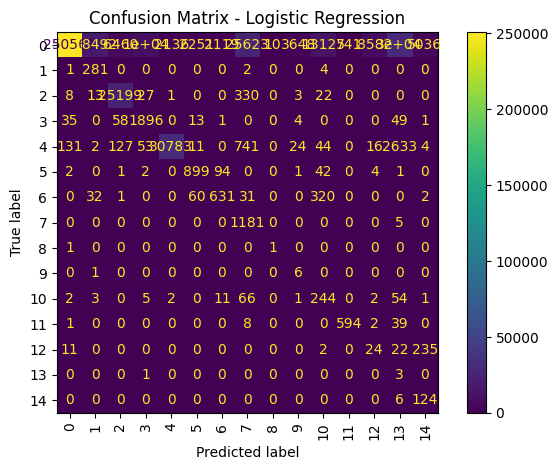


----------------------------------------------------------------------
Decision Tree
----------------------------------------------------------------------
Confusion Matrix:
[[376247    381     36     14    426     98     20    391      0      1
      79     14    529      2    826]
 [    14    274      0      0      0      0      0      0      0      0
       0      0      0      0      0]
 [    12      0  25589      0      2      0      0      0      0      0
       0      0      0      0      0]
 [    10      0      0   2040      1      2      2      0      0      0
       0      0      0      2      0]
 [    24      0      1     16  34497      0      0      0      0      0
      31      0      0      0      0]
 [     1      0      0      0      0   1039      6      0      0      0
       0      0      0      0      0]
 [     1      0      0      1      0      2   1071      0      0      0
       0      0      2      0      0]
 [     3      0      0      0      0      0      0   11

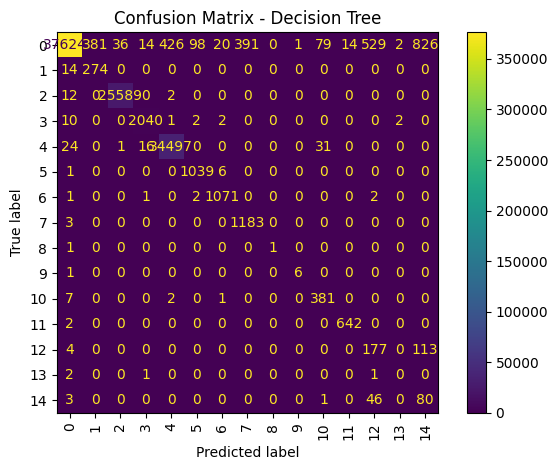


----------------------------------------------------------------------
Random Forest
----------------------------------------------------------------------
Confusion Matrix:
[[377508    483     13     20    594     50      0      2      0      1
      23      0      8      0    362]
 [     6    282      0      0      0      0      0      0      0      0
       0      0      0      0      0]
 [    12      0  25588      0      3      0      0      0      0      0
       0      0      0      0      0]
 [     4      0      0   2051      0      2      0      0      0      0
       0      0      0      0      0]
 [    25      0      1      9  34521      0      0      0      0      0
      13      0      0      0      0]
 [     5      0      0      0      0   1037      4      0      0      0
       0      0      0      0      0]
 [     3      0      0      0      0      1   1072      0      0      0
       0      0      1      0      0]
 [     3      0      0      0      0      0      0   11

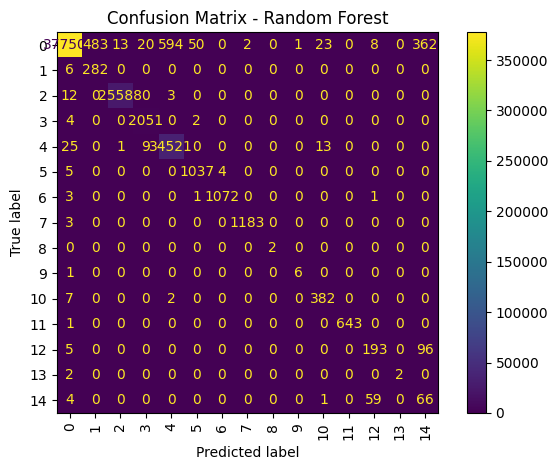

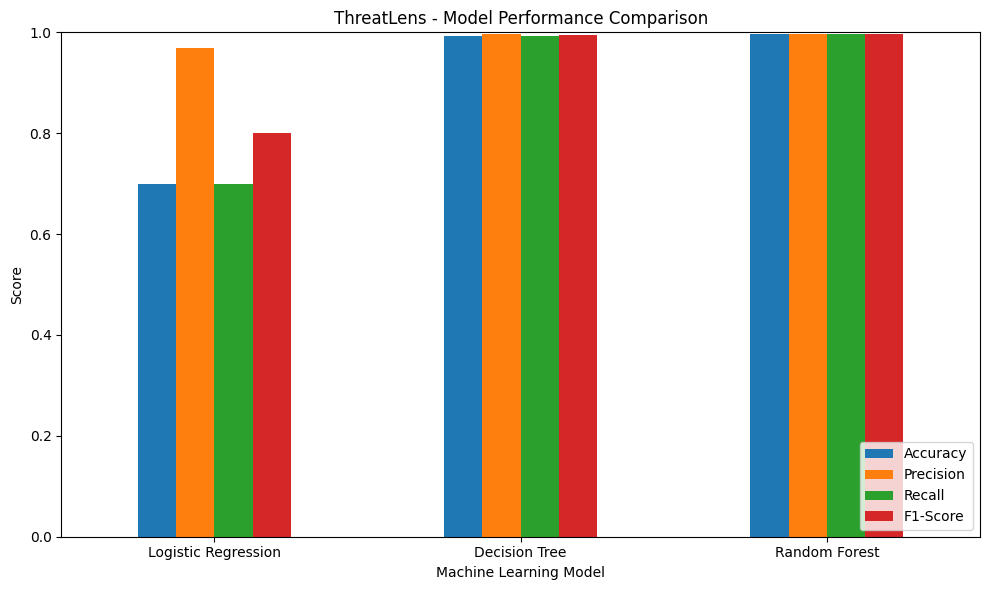


✓ Evaluation results saved as:
/content/ThreatLens_Model_Evaluation.csv

TASK 6 - STEP 10 COMPLETED

All three models have been evaluated using:

✓ Accuracy
✓ Precision
✓ Recall
✓ F1-Score
✓ Classification Report
✓ Confusion Matrix

The performance comparison has also been saved.

Next:
Step 11 → Error and Misclassification Analysis



In [ ]:
# ============================================================
# THREATLENS - TASK 6
# STEP 10: MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 70)
print("THREATLENS - TASK 6")
print("STEP 10: MODEL EVALUATION")
print("=" * 70)


# ============================================================
# STEP 10.1 - DEFINE MODELS AND PREDICTIONS
# ============================================================

models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_decision_tree,
    "Random Forest": y_pred_random_forest
}


# ============================================================
# STEP 10.2 - CALCULATE EVALUATION METRICS
# ============================================================

results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(
        y_test_encoded,
        predictions
    )

    precision = precision_score(
        y_test_encoded,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test_encoded,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test_encoded,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })


# ============================================================
# STEP 10.3 - CREATE RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE")
print("=" * 70)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)


# ============================================================
# STEP 10.4 - PRINT CLASSIFICATION REPORTS
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORTS")
print("=" * 70)


for model_name, predictions in models.items():

    print("\n" + "-" * 70)
    print(model_name)
    print("-" * 70)

    print(
        classification_report(
            y_test_encoded,
            predictions,
            zero_division=0
        )
    )


# ============================================================
# STEP 10.5 - CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)


for model_name, predictions in models.items():

    cm = confusion_matrix(
        y_test_encoded,
        predictions
    )

    print("\n" + "-" * 70)
    print(model_name)
    print("-" * 70)

    print("Confusion Matrix:")
    print(cm)

    # Display graphical confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm
    )

    disp.plot(
        xticks_rotation="vertical"
    )

    plt.title(
        f"Confusion Matrix - {model_name}"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# STEP 10.6 - METRIC COMPARISON GRAPH
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("ThreatLens - Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# ============================================================
# STEP 10.7 - SAVE RESULTS
# ============================================================

results_df.to_csv(
    "/content/ThreatLens_Model_Evaluation.csv",
    index=False
)

print("\n✓ Evaluation results saved as:")
print("/content/ThreatLens_Model_Evaluation.csv")


# ============================================================
# FINAL MESSAGE
# ============================================================

print("\n" + "=" * 70)
print("TASK 6 - STEP 10 COMPLETED")
print("=" * 70)

print("""
All three models have been evaluated using:

✓ Accuracy
✓ Precision
✓ Recall
✓ F1-Score
✓ Classification Report
✓ Confusion Matrix

The performance comparison has also been saved.

Next:
Step 11 → Error and Misclassification Analysis
""")

In [ ]:
# ============================================================
# THREATLENS - TASK 6
# STEP 11: ERROR AND MISCLASSIFICATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("THREATLENS - TASK 6")
print("STEP 11: ERROR AND MISCLASSIFICATION ANALYSIS")
print("=" * 70)


# ============================================================
# STEP 11.1 - DEFINE MODELS AND PREDICTIONS
# ============================================================

print("\n[11.1] Preparing model predictions...")

models = {
    "Logistic Regression": np.asarray(y_pred_logistic),
    "Decision Tree": np.asarray(y_pred_decision_tree),
    "Random Forest": np.asarray(y_pred_random_forest)
}

y_actual = np.asarray(y_test_encoded)

print("✓ Actual test labels loaded")
print("✓ Predictions for all three models loaded")

print("\nNumber of test samples:", len(y_actual))


# ============================================================
# STEP 11.2 - CREATE ATTACK-NAME MAPPING
# ============================================================

print("\n[11.2] Checking class-label mapping...")

# Try to automatically find an existing LabelEncoder
label_encoder_found = False

possible_encoders = [
    "label_encoder",
    "le",
    "encoder",
    "target_encoder"
]

for encoder_name in possible_encoders:

    if encoder_name in globals():

        encoder_object = globals()[encoder_name]

        if hasattr(encoder_object, "classes_"):

            label_encoder = encoder_object
            label_encoder_found = True

            print(
                f"✓ Label encoder found: {encoder_name}"
            )

            break


# ------------------------------------------------------------
# If LabelEncoder exists, use its class names
# ------------------------------------------------------------

if label_encoder_found:

    class_names = list(label_encoder.classes_)

    print("\nEncoded label → Attack/Class mapping:")

    for index, class_name in enumerate(class_names):

        print(
            f"  {index} → {class_name}"
        )


# ------------------------------------------------------------
# If no LabelEncoder exists
# ------------------------------------------------------------

else:

    unique_labels = np.sort(
        np.unique(y_actual)
    )

    class_names = [
        str(label)
        for label in unique_labels
    ]

    print(
        "\n⚠ No LabelEncoder object was found."
    )

    print(
        "Using encoded labels for the analysis."
    )

    print(
        "\nEncoded classes found:"
    )

    for label in unique_labels:

        print(
            f"  {label} → {label}"
        )


# ============================================================
# STEP 11.3 - FUNCTION TO CONVERT LABEL TO ATTACK NAME
# ============================================================

def get_class_name(label):

    try:

        label_int = int(label)

        if (
            label_encoder_found
            and label_int < len(class_names)
        ):

            return str(
                class_names[label_int]
            )

    except:

        pass

    return str(label)


# ============================================================
# STEP 11.4 - CREATE ERROR SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ERROR SUMMARY")
print("=" * 70)


error_results = []

for model_name, predictions in models.items():

    correct = np.sum(
        y_actual == predictions
    )

    errors = np.sum(
        y_actual != predictions
    )

    total = len(y_actual)

    error_rate = (
        errors / total
    )

    error_results.append({
        "Model": model_name,
        "Total Samples": total,
        "Correct Predictions": correct,
        "Misclassified Samples": errors,
        "Error Rate": error_rate
    })


error_summary_df = pd.DataFrame(
    error_results
)

error_summary_df["Error Rate"] = (
    error_summary_df["Error Rate"] * 100
).round(2)


display(error_summary_df)


# ============================================================
# STEP 11.5 - MISCLASSIFICATION TABLE
# ============================================================

def create_misclassification_table(
    y_actual,
    predictions
):

    data = pd.DataFrame({

        "Actual_Encoded": y_actual,

        "Predicted_Encoded": predictions

    })

    # Keep only incorrect predictions
    errors = data[
        data["Actual_Encoded"]
        != data["Predicted_Encoded"]
    ].copy()

    if len(errors) == 0:

        return pd.DataFrame()

    # Convert encoded values to attack names
    errors["Actual"] = errors[
        "Actual_Encoded"
    ].apply(get_class_name)

    errors["Predicted"] = errors[
        "Predicted_Encoded"
    ].apply(get_class_name)

    # Count repeated Actual → Predicted errors
    error_counts = (
        errors
        .groupby(
            ["Actual", "Predicted"]
        )
        .size()
        .reset_index(
            name="Number of Errors"
        )
        .sort_values(
            "Number of Errors",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return error_counts


# ============================================================
# STEP 11.6 - LOGISTIC REGRESSION ERRORS
# ============================================================

print("\n" + "=" * 70)
print("LOGISTIC REGRESSION - MISCLASSIFICATION ANALYSIS")
print("=" * 70)

logistic_errors = create_misclassification_table(
    y_actual,
    models["Logistic Regression"]
)

if len(logistic_errors) == 0:

    print("\n✓ No misclassified samples.")

else:

    print(
        "\nActual Attack → Predicted Attack"
    )

    display(logistic_errors)


# ============================================================
# STEP 11.7 - DECISION TREE ERRORS
# ============================================================

print("\n" + "=" * 70)
print("DECISION TREE - MISCLASSIFICATION ANALYSIS")
print("=" * 70)

decision_tree_errors = create_misclassification_table(
    y_actual,
    models["Decision Tree"]
)

if len(decision_tree_errors) == 0:

    print("\n✓ No misclassified samples.")

else:

    print(
        "\nActual Attack → Predicted Attack"
    )

    display(decision_tree_errors)


# ============================================================
# STEP 11.8 - RANDOM FOREST ERRORS
# ============================================================

print("\n" + "=" * 70)
print("RANDOM FOREST - MISCLASSIFICATION ANALYSIS")
print("=" * 70)

random_forest_errors = create_misclassification_table(
    y_actual,
    models["Random Forest"]
)

if len(random_forest_errors) == 0:

    print("\n✓ No misclassified samples.")

else:

    print(
        "\nActual Attack → Predicted Attack"
    )

    display(random_forest_errors)


# ============================================================
# STEP 11.9 - MOST COMMON MISCLASSIFICATION
# ============================================================

print("\n" + "=" * 70)
print("MOST COMMON MISCLASSIFICATION")
print("=" * 70)


def show_most_common_error(
    error_table,
    model_name
):

    print("\n" + model_name)
    print("-" * 50)

    if len(error_table) == 0:

        print("No classification errors.")

        return

    row = error_table.iloc[0]

    print(
        "Actual class    :",
        row["Actual"]
    )

    print(
        "Predicted class :",
        row["Predicted"]
    )

    print(
        "Number of errors:",
        int(row["Number of Errors"])
    )


show_most_common_error(
    logistic_errors,
    "Logistic Regression"
)

show_most_common_error(
    decision_tree_errors,
    "Decision Tree"
)

show_most_common_error(
    random_forest_errors,
    "Random Forest"
)


# ============================================================
# STEP 11.10 - ERROR DISTRIBUTION BY ACTUAL ATTACK
# ============================================================

print("\n" + "=" * 70)
print("ERROR DISTRIBUTION BY ACTUAL ATTACK CLASS")
print("=" * 70)


def actual_class_error_distribution(
    y_actual,
    predictions,
    model_name
):

    data = pd.DataFrame({

        "Actual": y_actual,

        "Predicted": predictions
    })

    # Only incorrect predictions
    errors = data[
        data["Actual"] != data["Predicted"]
    ].copy()

    if len(errors) == 0:

        print(
            f"\n{model_name}: No errors."
        )

        return

    errors["Actual Attack"] = errors[
        "Actual"
    ].apply(get_class_name)

    distribution = (
        errors["Actual Attack"]
        .value_counts()
        .reset_index()
    )

    distribution.columns = [
        "Actual Attack",
        "Number of Misclassifications"
    ]

    print(f"\n{model_name}")

    display(distribution)


actual_class_error_distribution(
    y_actual,
    models["Logistic Regression"],
    "Logistic Regression"
)

actual_class_error_distribution(
    y_actual,
    models["Decision Tree"],
    "Decision Tree"
)

actual_class_error_distribution(
    y_actual,
    models["Random Forest"],
    "Random Forest"
)


# ============================================================
# STEP 11.11 - DISPLAY INDIVIDUAL MISCLASSIFIED SAMPLES
# ============================================================

print("\n" + "=" * 70)
print("INDIVIDUAL MISCLASSIFIED SAMPLES")
print("=" * 70)


def display_misclassified_samples(
    y_actual,
    predictions,
    model_name,
    number_of_samples=20
):

    indices = np.where(
        y_actual != predictions
    )[0]

    if len(indices) == 0:

        print(
            f"\n{model_name}: No errors."
        )

        return

    samples = pd.DataFrame({

        "Test Sample Index": indices,

        "Actual Attack": [
            get_class_name(
                y_actual[i]
            )
            for i in indices
        ],

        "Predicted Attack": [
            get_class_name(
                predictions[i]
            )
            for i in indices
        ]
    })

    print(f"\n{model_name}")

    print(
        f"Showing first "
        f"{min(number_of_samples, len(samples))} "
        f"misclassified samples:"
    )

    display(
        samples.head(number_of_samples)
    )


display_misclassified_samples(
    y_actual,
    models["Logistic Regression"],
    "Logistic Regression"
)

display_misclassified_samples(
    y_actual,
    models["Decision Tree"],
    "Decision Tree"
)

display_misclassified_samples(
    y_actual,
    models["Random Forest"],
    "Random Forest"
)


# ============================================================
# STEP 11.12 - COMPARE ERROR PATTERNS
# ============================================================

print("\n" + "=" * 70)
print("MODEL ERROR PATTERN COMPARISON")
print("=" * 70)


comparison_rows = []

for model_name, predictions in models.items():

    total_errors = np.sum(
        y_actual != predictions
    )

    unique_error_pairs = len(
        create_misclassification_table(
            y_actual,
            predictions
        )
    )

    comparison_rows.append({

        "Model": model_name,

        "Total Errors": total_errors,

        "Unique Misclassification Types":
            unique_error_pairs
    })


error_pattern_df = pd.DataFrame(
    comparison_rows
)

display(error_pattern_df)


# ============================================================
# STEP 11.13 - SAVE ERROR ANALYSIS RESULTS
# ============================================================

print("\n" + "=" * 70)
print("SAVING ERROR ANALYSIS")
print("=" * 70)


error_summary_df.to_csv(
    "/content/ThreatLens_Error_Summary.csv",
    index=False
)

if len(logistic_errors) > 0:

    logistic_errors.to_csv(
        "/content/ThreatLens_Logistic_Misclassifications.csv",
        index=False
    )

if len(decision_tree_errors) > 0:

    decision_tree_errors.to_csv(
        "/content/ThreatLens_DecisionTree_Misclassifications.csv",
        index=False
    )

if len(random_forest_errors) > 0:

    random_forest_errors.to_csv(
        "/content/ThreatLens_RandomForest_Misclassifications.csv",
        index=False
    )


error_pattern_df.to_csv(
    "/content/ThreatLens_Error_Pattern_Comparison.csv",
    index=False
)


print(
    "✓ Error summary saved:"
)
print(
    "/content/ThreatLens_Error_Summary.csv"
)

print(
    "✓ Misclassification tables saved."
)

print(
    "✓ Error pattern comparison saved."
)


# ============================================================
# STEP 11.14 - FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("TASK 6 - STEP 11 COMPLETED")
print("=" * 70)

print("""
Error and misclassification analysis completed.

Analysis performed:

✓ Total classification errors
✓ Error rate
✓ Actual vs predicted attack classes
✓ Most common misclassification
✓ Error distribution by attack class
✓ Individual misclassified samples
✓ Comparison of model error patterns
✓ Error analysis CSV files generated

The results can be used to identify:
- Which attack classes are difficult to distinguish
- Which attack classes are frequently misclassified
- Which types of errors occur across models
- Limitations of the trained machine learning models
""")

print("=" * 70)

THREATLENS - TASK 6
STEP 11: ERROR AND MISCLASSIFICATION ANALYSIS

[11.1] Preparing model predictions...
✓ Actual test labels loaded
✓ Predictions for all three models loaded

Number of test samples: 446362

[11.2] Checking class-label mapping...

⚠ No LabelEncoder object was found.
Using encoded labels for the analysis.

Encoded classes found:
  0 → 0
  1 → 1
  2 → 2
  3 → 3
  4 → 4
  5 → 5
  6 → 6
  7 → 7
  8 → 8
  9 → 9
  10 → 10
  11 → 11
  12 → 12
  13 → 13
  14 → 14

ERROR SUMMARY


,Model,Total Samples,Correct Predictions,Misclassified Samples,Error Rate
0,Logistic Regression,446362,312427,133935,30.01
1,Decision Tree,446362,443227,3135,0.70
2,Random Forest,446362,444536,1826,0.41



LOGISTIC REGRESSION - MISCLASSIFICATION ANALYSIS

Actual Attack → Predicted Attack


,Actual,Predicted,Number of Errors
0,0,13,30037
1,0,7,25623
2,0,1,18492
3,0,10,13125
4,0,3,10243
...,...,...,...
74,5,2,1
75,5,9,1
76,6,2,1
77,8,0,1



DECISION TREE - MISCLASSIFICATION ANALYSIS

Actual Attack → Predicted Attack


...


Random Forest
Showing first 20 misclassified samples:


,Test Sample Index,Actual Attack,Predicted Attack
0,16,4,10
1,319,0,14
2,526,0,1
3,780,4,0
4,900,0,4
5,1001,0,4
6,1871,3,0
7,1895,0,4
8,2175,0,4
9,2479,0,1



MODEL ERROR PATTERN COMPARISON


,Model,Total Errors,Unique Misclassification Types
0,Logistic Regression,133935,79
1,Decision Tree,3135,46
2,Random Forest,1826,35



SAVING ERROR ANALYSIS
✓ Error summary saved:
/content/ThreatLens_Error_Summary.csv
✓ Misclassification tables saved.
✓ Error pattern comparison saved.

TASK 6 - STEP 11 COMPLETED

Error and misclassification analysis completed.

Analysis performed:

✓ Total classification errors
✓ Error rate
✓ Actual vs predicted attack classes
✓ Most common misclassification
✓ Error distribution by attack class
✓ Individual misclassified samples
✓ Comparison of model error patterns
✓ Error analysis CSV files generated

The results can be used to identify:
- Which attack classes are difficult to distinguish
- Which attack classes are frequently misclassified
- Which types of errors occur across models
- Limitations of the trained machine learning models

